<a href="https://colab.research.google.com/github/yosr-hr/movie_recommendation_system/blob/main/notebooks/movie_recommendation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [8]:
import pandas as pd
import numpy as np

movies = pd.read_csv("/content/movies.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
movies.head()

,index,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,...,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,cast,crew,director
0,0,237000000,Action Adventure Fantasy Science Fiction,http://www.avatarmovie.com/,19995,culture clash future space war space colony so...,en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,...,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,Sam Worthington Zoe Saldana Sigourney Weaver S...,"[{'name': 'Stephen E. Rivkin', 'gender': 0, 'd...",James Cameron
1,1,300000000,Adventure Fantasy Action,http://disney.go.com/disneypictures/pirates/,285,ocean drug abuse exotic island east india trad...,en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,...,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,Johnny Depp Orlando Bloom Keira Knightley Stel...,"[{'name': 'Dariusz Wolski', 'gender': 2, 'depa...",Gore Verbinski
2,2,245000000,Action Adventure Crime,http://www.sonypictures.com/movies/spectre/,206647,spy based on novel secret agent sequel mi6,en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,...,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,Daniel Craig Christoph Waltz L\u00e9a Seydoux ...,"[{'name': 'Thomas Newman', 'gender': 2, 'depar...",Sam Mendes
3,3,250000000,Action Crime Drama Thriller,http://www.thedarkknightrises.com/,49026,dc comics crime fighter terrorist secret ident...,en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,...,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,Christian Bale Michael Caine Gary Oldman Anne ...,"[{'name': 'Hans Zimmer', 'gender': 2, 'departm...",Christopher Nolan
4,4,260000000,Action Adventure Science Fiction,http://movies.disney.com/john-carter,49529,based on novel mars medallion space travel pri...,en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,...,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,Taylor Kitsch Lynn Collins Samantha Morton Wil...,"[{'name': 'Andrew Stanton', 'gender': 2, 'depa...",Andrew Stanton


In [10]:
print("Number of rows:", movies.shape[0])
print("Number of columns:", movies.shape[1])

Number of rows: 4803
Number of columns: 24


In [11]:
print("Dataset columns:")
for column in movies.columns:
    print("-", column)

Dataset columns:
- index
- budget
- genres
- homepage
- id
- keywords
- original_language
- original_title
- overview
- popularity
- production_companies
- production_countries
- release_date
- revenue
- runtime
- spoken_languages
- status
- tagline
- title
- vote_average
- vote_count
- cast
- crew
- director


In [12]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 4803 non-null   int64  
 1   budget                4803 non-null   int64  
 2   genres                4775 non-null   object 
 3   homepage              1712 non-null   object 
 4   id                    4803 non-null   int64  
 5   keywords              4391 non-null   object 
 6   original_language     4803 non-null   object 
 7   original_title        4803 non-null   object 
 8   overview              4800 non-null   object 
 9   popularity            4803 non-null   float64
 10  production_companies  4803 non-null   object 
 11  production_countries  4803 non-null   object 
 12  release_date          4802 non-null   object 
 13  revenue               4803 non-null   int64  
 14  runtime               4801 non-null   float64
 15  spoken_languages     

In [13]:
movies.isnull().sum()

,0
index,0
budget,0
genres,28
homepage,3091
id,0
keywords,412
original_language,0
original_title,0
overview,3
popularity,0


In [14]:
print("Number of duplicate rows:", movies.duplicated().sum())

Number of duplicate rows: 0


In [42]:
#Numerical descriptive statistics
movies.describe()

,index,budget,id,popularity,revenue,runtime,vote_average,vote_count
count,4803.000000,4.803000e+03,4803.000000,4803.000000,4.803000e+03,4801.000000,4803.000000,4803.000000
mean,2401.000000,2.904504e+07,57165.484281,21.492301,8.226064e+07,106.875859,6.092172,690.217989
std,1386.651002,4.072239e+07,88694.614033,31.816650,1.628571e+08,22.611935,1.194612,1234.585891
min,0.000000,0.000000e+00,5.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,1200.500000,7.900000e+05,9014.500000,4.668070,0.000000e+00,94.000000,5.600000,54.000000
50%,2401.000000,1.500000e+07,14629.000000,12.921594,1.917000e+07,103.000000,6.200000,235.000000
75%,3601.500000,4.000000e+07,58610.500000,28.313505,9.291719e+07,118.000000,6.800000,737.000000
max,4802.000000,3.800000e+08,459488.000000,875.581305,2.787965e+09,338.000000,10.000000,13752.000000


In [43]:
#Categorical descriptive statistics
movies.describe(include="object")

,genres,homepage,keywords,original_language,original_title,overview,production_companies,production_countries,release_date,spoken_languages,status,tagline,title,cast,crew,director
count,4775,1712,4391,4803,4803,4800,4803,4803,4802,4803,4803,3959,4803,4760,4803,4773
unique,1168,1691,4219,37,4801,4800,3697,469,3280,544,3,3944,4800,4741,4776,2349
top,Drama,http://www.missionimpossible.com/,independent film,en,Batman,"In the 22nd century, a paraplegic Marine is di...",[],"[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2006-01-01,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,Based on a true story.,The Host,William Shatner Leonard Nimoy DeForest Kelley ...,[],Steven Spielberg
freq,370,4,55,4505,2,1,351,2977,10,3171,4795,3,2,6,28,27


In [45]:
#Check the number of unique values
movies.nunique()

,0
index,4803
budget,436
genres,1168
homepage,1691
id,4803
keywords,4219
original_language,37
original_title,4801
overview,4800
popularity,4802


the visualization part of EDA

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_style("whitegrid")

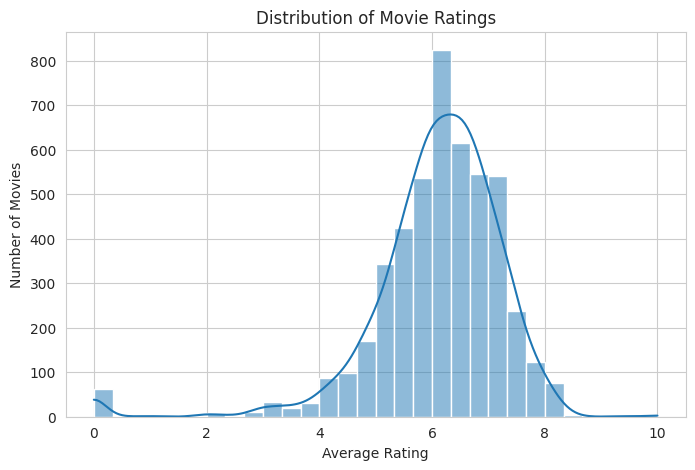

In [47]:
#Distribution of movie ratings
plt.figure(figsize=(8, 5))

sns.histplot(data=movies, x="vote_average", bins=30, kde=True)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Movies")

plt.show()

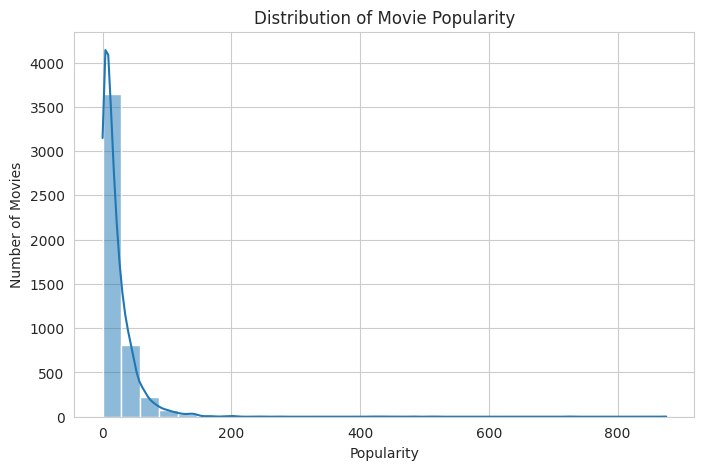

In [53]:
#Distribution of movie popularity
plt.figure(figsize=(8, 5))

sns.histplot(data=movies, x="popularity", bins=30, kde=True)

plt.title("Distribution of Movie Popularity")
plt.xlabel("Popularity")
plt.ylabel("Number of Movies")

plt.show()


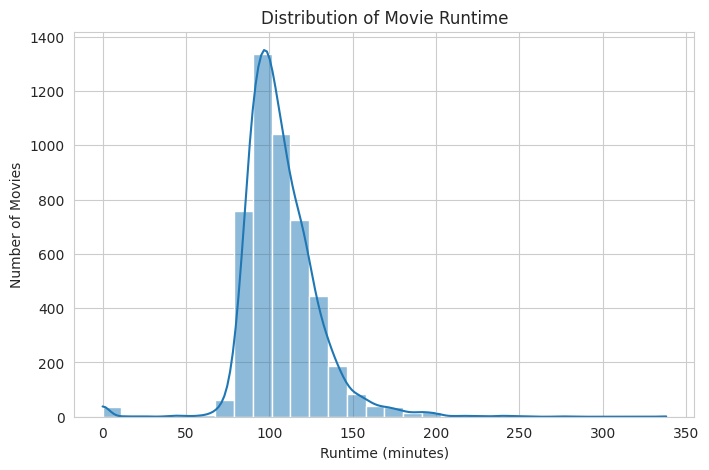

In [49]:
#Distribution of movie runtimes
plt.figure(figsize=(8, 5))

sns.histplot(data=movies, x="runtime", bins=30, kde=True)

plt.title("Distribution of Movie Runtime")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of Movies")

plt.show()

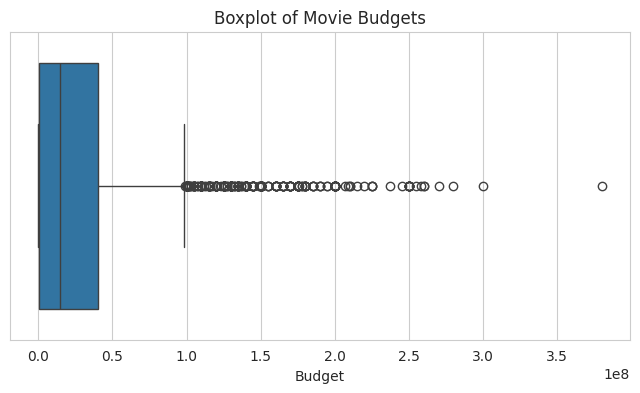

In [50]:
#Boxplots to identify outliers
plt.figure(figsize=(8, 4))

sns.boxplot(x=movies["budget"])

plt.title("Boxplot of Movie Budgets")
plt.xlabel("Budget")

plt.show()

What is an outlier?

An outlier is a value that is unusually far from most other observations.

For example, a movie with a budget of 300 million may be an outlier compared with movies having budgets of 10 million

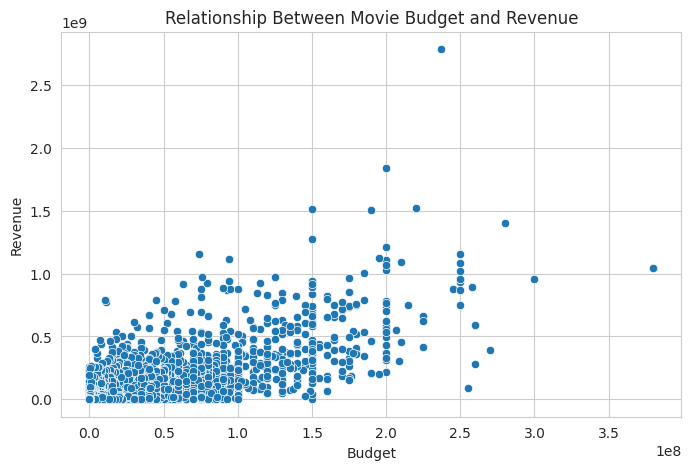

In [51]:
#Relationship between budget and revenue
plt.figure(figsize=(8, 5))

sns.scatterplot(data=movies, x="budget", y="revenue")

plt.title("Relationship Between Movie Budget and Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.show()

This is a scatter plot:
- Each point represents one movie
- The horizontal axis represents its budget
- The vertical axis represents its revenue

In [54]:
columns_to_check = [
    "runtime",
    "budget",
    "revenue",
    "vote_average",
    "popularity"
]

for column in columns_to_check:
    print(f"{column}:")
    print("Number of zero values:", (movies[column] == 0).sum())
    print()

runtime:
Number of zero values: 35

budget:
Number of zero values: 1037

revenue:
Number of zero values: 1427

vote_average:
Number of zero values: 63

popularity:
Number of zero values: 1



## 3. Data Preprocessing

In this section, we handle missing values, remove unnecessary columns,
and prepare the dataset for feature engineering.

In [15]:
# Create a copy of the original dataset
movies_clean = movies.copy()

# Fill missing values in text columns
text_columns = ["genres", "keywords", "overview", "cast", "director"]

for column in text_columns:
    movies_clean[column] = movies_clean[column].fillna("")

print("Missing values after preprocessing:")
print(movies_clean[text_columns].isnull().sum())

Missing values after preprocessing:
genres      0
keywords    0
overview    0
cast        0
director    0
dtype: int64


In [17]:
print("Dataset shape:", movies_clean.shape)

print("Total missing values:", movies_clean.isnull().sum().sum())
#to show where the missing values
remaining_missing = movies_clean.isnull().sum()

print(remaining_missing[remaining_missing > 0])

Dataset shape: (4803, 24)
Total missing values: 3938
homepage        3091
release_date       1
runtime            2
tagline          844
dtype: int64


In [18]:
#data inspection We're examining the internal structure of the features that will feed our recommendation algorithm
print("Example genres:")
print(movies_clean["genres"].iloc[0])

print("\nExample keywords:")
print(movies_clean["keywords"].iloc[0])

print("\nExample cast:")
print(movies_clean["cast"].iloc[0])

print("\nExample director:")
print(movies_clean["director"].iloc[0])

print("\nExample overview:")
print(movies_clean["overview"].iloc[0])

Example genres:
Action Adventure Fantasy Science Fiction

Example keywords:
culture clash future space war space colony society

Example cast:
Sam Worthington Zoe Saldana Sigourney Weaver Stephen Lang Michelle Rodriguez

Example director:
James Cameron

Example overview:
In the 22nd century, a paraplegic Marine is dispatched to the moon Pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization.


In [20]:
for column in text_columns:
    print(column, ":", movies_clean[column].iloc[0].islower())

genres : False
keywords : True
overview : False
cast : False
director : False


In [23]:
#Apply text normalization(so that for exemple :Action, action, and ACTION should be treated as the same word)
# Convert text features to lowercase and remove extra spaces
for column in text_columns:
    movies_clean[column] = (
        movies_clean[column]
        .astype(str)
        .str.lower()
        .str.strip()
    )

In [24]:
#verification
for column in text_columns:
    print(column, ":", movies_clean[column].iloc[0].islower())

genres : True
keywords : True
overview : True
cast : True
director : True


In [25]:
recommendation_features = [
    "id",
    "title",
    "genres",
    "keywords",
    "overview",
    "cast",
    "director"
]

movies_model = movies_clean[recommendation_features].copy()

movies_model.head()

,id,title,genres,keywords,overview,cast,director
0,19995,Avatar,action adventure fantasy science fiction,culture clash future space war space colony so...,"in the 22nd century, a paraplegic marine is di...",sam worthington zoe saldana sigourney weaver s...,james cameron
1,285,Pirates of the Caribbean: At World's End,adventure fantasy action,ocean drug abuse exotic island east india trad...,"captain barbossa, long believed to be dead, ha...",johnny depp orlando bloom keira knightley stel...,gore verbinski
2,206647,Spectre,action adventure crime,spy based on novel secret agent sequel mi6,a cryptic message from bond’s past sends him o...,daniel craig christoph waltz l\u00e9a seydoux ...,sam mendes
3,49026,The Dark Knight Rises,action crime drama thriller,dc comics crime fighter terrorist secret ident...,following the death of district attorney harve...,christian bale michael caine gary oldman anne ...,christopher nolan
4,49529,John Carter,action adventure science fiction,based on novel mars medallion space travel pri...,"john carter is a war-weary, former military ca...",taylor kitsch lynn collins samantha morton wil...,andrew stanton


**Feature Engineering** before vectorization because we first need to decide what information represents each movie then convert that information into numbers

In [27]:
# Combine all textual features into one column

movies_model["tags"] = (
    movies_model["genres"] + " " +
    movies_model["keywords"] + " " +
    movies_model["overview"] + " " +
    movies_model["cast"] + " " +
    movies_model["director"]
)
movies_model[["title", "tags"]].head()
print(movies_model.loc[0, "tags"])
print("Number of movies:", len(movies_model))
print("Number of columns:", movies_model.shape[1]) #(7 original selected features + tags)
print("Missing tags:", movies_model["tags"].isnull().sum())

action adventure fantasy science fiction culture clash future space war space colony society in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization. sam worthington zoe saldana sigourney weaver stephen lang michelle rodriguez james cameron
Number of movies: 4803
Number of columns: 8
Missing tags: 0


In [28]:
#now Text Vectorization with TF-IDF(Term Frequency – Inverse Document Frequency)
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=5000) #max_features is an hyperparameter Illustrative example only. Actual vocabulary selection depends on term frequency
tfidf_matrix = tfidf.fit_transform(movies_model["tags"])


In [29]:
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of unique words:", len(tfidf.get_feature_names_out()))
print(tfidf.get_feature_names_out()[:30])

TF-IDF matrix shape: (4803, 5000)
Number of unique words: 5000
['000' '007' '10' '100' '11' '12' '13' '14' '15' '16' '17' '18' '18th'
 '19' '1930s' '1950s' '1960s' '1970s' '1980s' '19th' '20' '200' '20th'
 '24' '25' '30' '3d' '40' '50' '60']


In [35]:
from sklearn.metrics.pairwise import cosine_similarity
similarity = cosine_similarity(tfidf_matrix)
print("Similarity matrix shape:", similarity.shape) # (4803,4803)-->scikit-learn compares each movie with every other movie

Similarity matrix shape: (4803, 4803)


the recommendation function

In [40]:
def recommend(movie):

    # Find the index of the selected movie
    movie_index = movies_model[movies_model["title"] == movie].index[0]

    # Get similarity scores for this movie
    distances = similarity[movie_index]

    # Sort movies by similarity score
    movies_list = sorted(
        list(enumerate(distances)),
        reverse=True,
        key=lambda x: x[1]
    )[1:6]

    # Display recommended movies
    for i in movies_list:
        print(movies_model.iloc[i[0]].title)

In [41]:
#for test
recommend("Avatar")

Moonraker
Lifeforce
Lost in Space
Cargo
Aliens
